# MVP plan

The plan compares LLM twins with supervised models on survey answers that depend on the state of the economy. It uses one training window and one evaluation window, and every variable is chosen by a fixed rule. It replaces the proposal in Part 2 of `01_data_and_mvp_proposal.ipynb`; Part 1 of that notebook describes the data. It is a starting point, and details will be refined during implementation.

| | |
|---|---|
| **Question** | Given the same inputs as a supervised model, does an LLM predict state-dependent answers better? |
| **Outcomes** | The five items of the Index of Consumer Sentiment, three classes each |
| **Inputs** | 11 respondent attributes and 5 state variables, the same for both families |
| **Train** | February 2017 to July 2024 (telephone, plus web from April 2024) |
| **Evaluate** | August 2024 to February 2026 (web only) |
| **Twins** | Llama 3.1 8B Instruct, zero-shot, read from answer-code probabilities; plus an intercept-shifted variant |
| **Supervised** | Multinomial logit with respondent party × president's party; gradient boosting |
| **Scores** | Individual log loss; population and party net balance, split into a level error and a change error |

**What is being tested.** An LLM can bring three kinds of knowledge to an evaluation month:

- **The outcomes themselves**, which the knowledge horizon (W2) excludes.
- **Specific knowledge** of particular people, events or situations known at the horizon. The inputs limit it, since they give parties rather than names and no dates. They can't remove it: a state that resembles a period in pretraining can cue what was happening then.
- **Structural knowledge** of how people generally respond to conditions.

Both families see the same inputs, so the comparison measures what the LLM adds to them: structural knowledge, plus whatever specific knowledge the inputs cue.

Decisions are made in this order, each using only the results of the ones before it: **variables → twin model → windows → scores.**

In [1]:
from pathlib import Path
import re, textwrap
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 160)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
DATA = ROOT / 'data'

# Same chart style as notebook 01
SURFACE, INK, INK2, MUTED, GRID, AXIS, NEUTRAL = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#d3d1c9'
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE, 'figure.dpi': 110,
    'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica Neue', 'Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size': 9.5, 'axes.titlesize': 11, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'axes.titlecolor': INK, 'text.color': INK, 'axes.edgecolor': AXIS, 'axes.spines.top': False,
    'axes.spines.right': False, 'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK2,
    'ytick.labelcolor': INK2, 'xtick.major.size': 0, 'ytick.major.size': 0})
T = pd.Timestamp

df = pd.read_csv(DATA / 'data.csv', skipinitialspace=True)
win = pd.read_csv(DATA / 'external' / 'sca' / 'interview_windows.csv', parse_dates=['interview_start', 'interview_end'])
LAST = df.YYYYMM.max()
print(f'{df.shape[1]} columns, {len(df):,} interviews, {df.YYYYMM.min()}–{LAST}')

118 columns, 342,345 interviews, 197801–202602


## 1. Variables

Each of the 118 columns is first given one role: a design field, a format flag, a derived index score, a **respondent attribute** (who the person is), or an **answer** (what they think about the economy). Inputs come only from attributes and outcomes only from answers, so no column can be both.

**Explanatory rules**, applied in order:

- **E1** It is a respondent attribute: demographics, household, holdings or party.
- **E2** It is asked of every respondent, not a follow-up routed to a subgroup.
- **E3** It is in the current questionnaire, meaning it has values in the last archived month.
- **E4** One column per concept: Michigan's harmonised recode or, for income, the finest year-relative quantile.

**Outcome rules**:

- **O1** It is an answer.
- **O2** It is the main answer, not a coded reason or a sub-step of a multi-part question.
- **O3** It enters the Index of Consumer Sentiment, whose five items are listed in `Index Calculation.pdf`.

In [2]:
DESIGN = ['CASEID', 'YYYYMM', 'YYYYQ', 'YYYY', 'ID', 'IDPREV', 'DATEPR', 'IDPREV2', 'DATEPR2', 'SAMPLE', 'METHOD',
          'WT', 'WT_HH', 'WT_QUINTMED']
FORMAT = ['INCQFM', 'HOMEQFM', 'INVQFM']                       # how an amount was recorded (exact or bracket)
INDEX = ['ICS', 'ICC', 'ICE']
ATTRIBUTE = (['INCOME', 'YTL10', 'YTL90', 'YTL50', 'YTL5', 'YTL4', 'YTL3', 'HOMEOWN', 'HOMEAMT']
             + [f'HTL{q}' for q in (10, 90, 50, 5, 4, 3)] + ['INVEST', 'INVAMT'] + [f'STL{q}' for q in (10, 90, 50, 5, 4, 3)]
             + ['AGE', 'BIRTHM', 'BIRTHY', 'REGION', 'SEX', 'MARRY', 'NUMKID', 'NUMADT', 'EDUC', 'ECLGRD', 'EHSGRD',
                'EGRADE', 'EDUCATION', 'POLAFF', 'POLREP', 'POLDEM', 'POLCRD', 'VEHOWN', 'VEHNUM'])
ANSWER = [c for c in df.columns if c not in DESIGN + FORMAT + INDEX + ATTRIBUTE]
assert sorted(DESIGN + FORMAT + INDEX + ATTRIBUTE + ANSWER) == sorted(df.columns)

# E2: follow-ups and the answer that routes to them. The check below confirms each is blank outside its gate.
SENTINEL = {'HOMEAMT': 9999998, 'INVAMT': 99999998}
ROUTED = {**{c: ('HOMEOWN', {1}) for c in ['HOMEAMT'] + [f'HTL{q}' for q in (10, 90, 50, 5, 4, 3)]},
          **{c: ('INVEST', {1}) for c in ['INVAMT'] + [f'STL{q}' for q in (10, 90, 50, 5, 4, 3)]},
          'POLREP': ('POLAFF', {1}), 'POLDEM': ('POLAFF', {2}), 'POLCRD': ('POLAFF', {3, 8, 9}), 'VEHNUM': ('VEHOWN', {1})}
def filled(c):
    s = df[c]
    return (s.where(s < SENTINEL[c]) if c in SENTINEL else s).notna()
leak = {c: filled(c)[~df[g].isin(v)].mean() for c, (g, v) in ROUTED.items()}
assert max(leak.values()) < 0.001, leak

# E3: has values in the last archived month
current = {c: df.loc[df.YYYYMM == LAST, c].notna().any() for c in df.columns}

# E4: concepts with more than one column, and the one kept
CONCEPTS = {'income': (['INCOME', 'YTL10', 'YTL90', 'YTL50', 'YTL5', 'YTL4', 'YTL3'], 'YTL5'),
            'age': (['AGE', 'BIRTHY', 'BIRTHM'], 'AGE'),
            'education': (['EDUC', 'ECLGRD', 'EHSGRD', 'EGRADE', 'EDUCATION'], 'EDUC')}
redundant = [c for cols, keep in CONCEPTS.values() for c in cols if c != keep]

# O2: coded reasons and sub-steps (direction or amount steps of a recoded answer)
REASON = [c for c in ANSWER if re.fullmatch(r'(PAGOR|DURRN|HOMRN|SHOMRN|CARRN|NEWS)\d', c)]
SUBSTEP = [c for c in ANSWER if re.search(r'Q\d$', c)] + ['GASPX1', 'GASPX2', 'GAS1PX1', 'GAS1PX2']
INDEX_ITEMS = ['PAGO', 'PEXP', 'BUS12', 'BUS5', 'DUR']        # x1..x5 in Index Calculation.pdf

def funnel(steps, start):
    out, keep = [('All columns', list(start), [])], list(start)
    for label, test in steps:
        new = [c for c in keep if test(c)]
        out.append((label, new, [c for c in keep if c not in new])); keep = new
    return out

EXPL = funnel([('E1  respondent attribute', lambda c: c in ATTRIBUTE),
               ('E2  asked of everyone', lambda c: c not in ROUTED),
               ('E3  in current questionnaire', lambda c: current[c]),
               ('E4  one column per concept', lambda c: c not in redundant)], df.columns)
OUTC = funnel([('O1  an answer', lambda c: c in ANSWER),
               ('O2  main answer', lambda c: c not in REASON + SUBSTEP),
               ('O3  enters the sentiment index', lambda c: c in INDEX_ITEMS)], df.columns)
EXPLANATORY, OUTCOMES = EXPL[-1][1], OUTC[-1][1]
print('Explanatory:', EXPLANATORY); print('Outcomes:   ', OUTCOMES)

Explanatory: ['YTL5', 'HOMEOWN', 'INVEST', 'AGE', 'REGION', 'SEX', 'MARRY', 'NUMKID', 'NUMADT', 'EDUC', 'POLAFF']
Outcomes:    ['PAGO', 'PEXP', 'BUS12', 'BUS5', 'DUR']


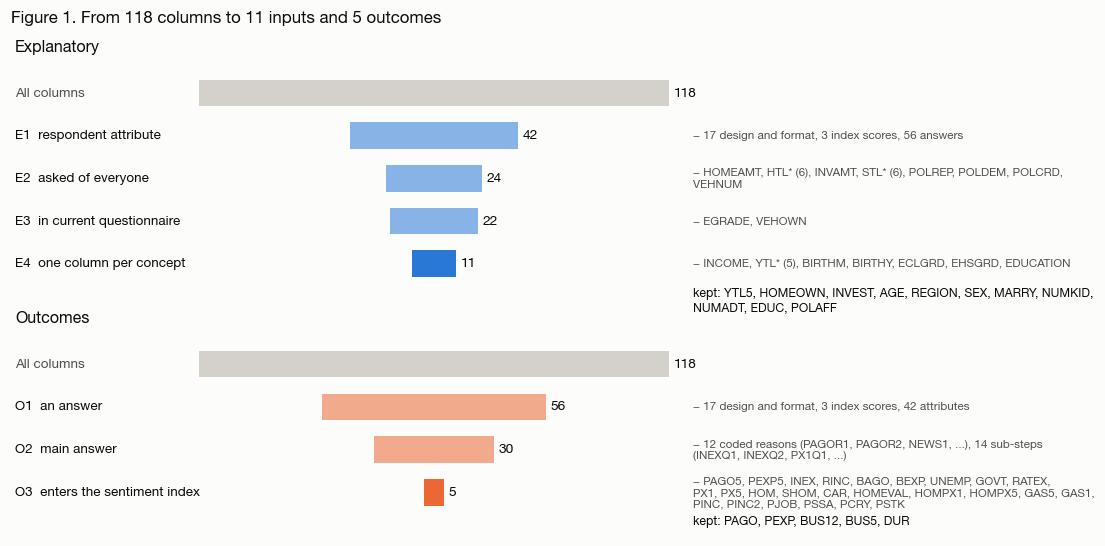

In [3]:
def short(cols):
    # Collapse families like HTL10, HTL90, ... into 'HTL* (6)'
    fam = {}
    for c in cols:
        m = re.fullmatch(r'([A-Z]+TL)\d+', c); fam.setdefault(m.group(1) + '*' if m else c, []).append(c)
    return ', '.join(k if len(v) == 1 else f'{k} ({len(v)})' for k, v in fam.items())

def why_dropped(label, dropped):
    if label.startswith(('E1', 'O1')):
        n = lambda grp: sum(c in grp for c in dropped)
        parts = [f'{n(DESIGN + FORMAT)} design and format', f'{n(INDEX)} index scores']
        parts.append(f'{n(ANSWER)} answers' if label.startswith('E1') else f'{n(ATTRIBUTE)} attributes')
        return ', '.join(parts)
    if label.startswith('O2'):
        return (f'{sum(c in REASON for c in dropped)} coded reasons ({", ".join(REASON[:3])}, ...), '
                f'{sum(c in SUBSTEP for c in dropped)} sub-steps ({", ".join(SUBSTEP[:3])}, ...)')
    return short(dropped)

blocks = [('Explanatory', EXPL, BLUE), ('Outcomes', OUTC, ORANGE)]
nrows = sum(len(b[1]) for b in blocks) + 1
fig, ax = plt.subplots(figsize=(11, 0.52 * nrows + 0.6))
y, half = 0, 59
for title, steps, color in blocks:
    ax.text(-half - 46, y - 0.15, title, fontsize=10.5, fontweight='semibold', va='bottom')
    y += 0.75
    for i, (label, kept, dropped) in enumerate(steps):
        n = len(kept); final = i == len(steps) - 1
        ax.barh(y, n, left=-n / 2, height=0.62, color=color if i else NEUTRAL, alpha=1 if final or i == 0 else 0.55, lw=0)
        ax.text(-half - 46, y, label, va='center', fontsize=8.8, color=INK if i else INK2)
        ax.text(max(n / 2, 2.5) + 1.2, y, str(n), va='center', fontsize=9, fontweight='semibold', color=INK)
        if dropped:
            txt = textwrap.fill('− ' + why_dropped(label, dropped), 62)
            ax.text(half + 6, y, txt, va='center', fontsize=7.6, color=INK2, linespacing=1.15)
        if final:
            ax.text(half + 6, y + 0.55, textwrap.fill('kept: ' + ', '.join(kept), 62), va='top', fontsize=8,
                    color=INK, fontweight='semibold')
        y += 1 if not final else 1.6
ax.set_xlim(-half - 47, half + 70); ax.set_ylim(y - 0.6, -0.4); ax.axis('off')
ax.set_title('Figure 1. From 118 columns to 11 inputs and 5 outcomes', pad=14)
plt.show()

**Notes on Figure 1.**

- E2 is checked in the data: every routed column is blank whenever its gate answer is absent (the `assert` above). For example, `POLREP` is filled only for Republicans.
- E4 keeps one column per concept:
  - `YTL5` for income, because dollar amounts aren't comparable across years and the quintile is the finest year-relative code.
  - `AGE` for age, Michigan's recode of birth date.
  - `EDUC` for education, harmonised across phone and web.

**Coding.**

| Outcome | Favourable | Middle | Unfavourable |
|---|---|---|---|
| `PAGO`, `PEXP` | 1 better off | 3 same | 5 worse off |
| `BUS12` | 1, 2 good times | 3 partly good, partly bad | 4, 5 bad times |
| `BUS5` | 1, 2 continuous good times | 3 pro-con | 4, 5 bad times |
| `DUR` | 1 good time to buy | 3 pro-con | 5 bad time |

- The mapping comes from the codebook and is applied once, before any fitting. "Don't know" and "not ascertained" rows are dropped per item from training, the intercept fit and evaluation.
- Predicted shares add up to ICS, ICC and ICE with Michigan's formula.
- Missing explanatory values get their own "not reported" level in both families. Nothing is imputed.

## 2. State variables

**Rule S.** One official series for each economic quantity named by a question that has been asked every month since 1978:

| Quantity (question) | Series | Value used |
|---|---|---|
| Prices (`PX1`, `PX5`) | CPI-U, 12-month change | Latest release published before the interview window opens, as first published (ALFRED) |
| Unemployment (`UNEMP`) | Unemployment rate | Same |
| Interest rates (`RATEX`) | Effective federal funds rate | Same |
| Government (`GOVT`) | Party of the sitting president, and party of the most recent election winner (the two differ from November to January) | On the day the window opens |

Both families get these inputs together with the respondent attributes:

- **Supervised models:** as features, plus a web indicator.
- **Twins:** as text, with the web question wording and an instruction that the survey is online.

## 3. Windows

- **W1** Training starts in the first month after which all 11 inputs are asked every month.
- **W2** Training ends with the last interview window that closes before the twin's **knowledge horizon**. The horizon is the latest dated training data on the model card, or the release date if that isn't given. Llama 3.1's model card and technical report date only the pretraining data (to the end of 2023); post-training ran in several rounds with no dates given, so its horizon is its release, 23 July 2024.
- **W3** Evaluation runs from the next month to the last archived month.

In [4]:
asked = pd.DataFrame({c: filled(c) for c in EXPLANATORY}).groupby(df.YYYYMM).mean() > 0.5
starts = {c: asked.index[~asked[c]].max() for c in EXPLANATORY}           # last month the column was missing
binding = max(starts, key=starts.get)
TRAIN_START = int(asked.index[asked.index > starts[binding]].min())
HORIZON = T('2024-07-23')                                                 # Llama 3.1 release
TRAIN_END = int(win.loc[win.interview_end < HORIZON, 'YYYYMM'].max())
EVAL_START = int(win.loc[win.YYYYMM > TRAIN_END, 'YYYYMM'].min())
print(f'W1: train starts {TRAIN_START} (binding column: {binding})')
print(f'W2: train ends {TRAIN_END} (window closes {win.set_index("YYYYMM").interview_end[TRAIN_END]:%d %b %Y})')
print(f'W3: evaluate {EVAL_START}–{LAST}')

PERIODS = [('Baseline', EVAL_START, 202410), ('Flip', 202411, 202501), ('Tariffs', 202502, LAST)]
d = df[df.YYYYMM >= TRAIN_START]
rows = [('Train', d[d.YYYYMM <= TRAIN_END])] + [(p, d[d.YYYYMM.between(a, b)]) for p, a, b in PERIODS]
tab = pd.DataFrame({name: {'first': g.YYYYMM.min(), 'last': g.YYYYMM.max(), 'months': g.YYYYMM.nunique(),
                           'interviews': len(g), 'of which web': int((g.METHOD == 2).sum())} for name, g in rows}).T
tab.loc['Evaluate (all)'] = [EVAL_START, LAST, d[d.YYYYMM >= EVAL_START].YYYYMM.nunique(),
                             (d.YYYYMM >= EVAL_START).sum(), int(((d.YYYYMM >= EVAL_START) & (d.METHOD == 2)).sum())]
print(tab.to_string())

W1: train starts 201702 (binding column: POLAFF)
W2: train ends 202407 (window closes 22 Jul 2024)
W3: evaluate 202408–202602
                 first    last  months  interviews  of which web
Train           201702  202407      90       55867          2257
Baseline        202408  202410       3        3067          3067
Flip            202411  202501       3        2711          2711
Tariffs         202502  202602      13       15405         15405
Evaluate (all)  202408  202602      19       21183         21183


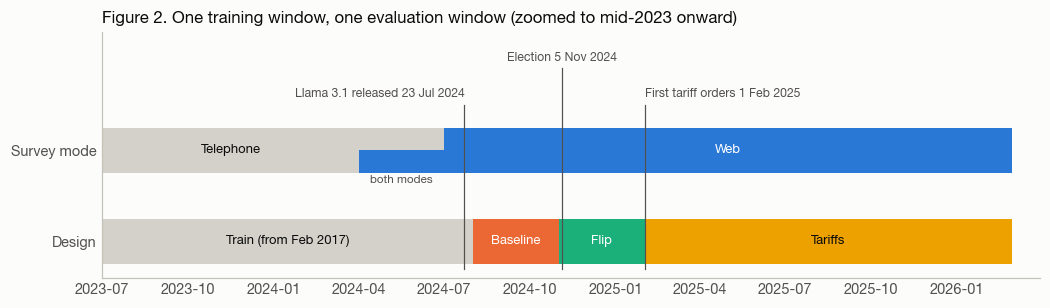

In [5]:
ym = lambda m: T(f'{m // 100}-{m % 100:02d}-01')
end = lambda m: ym(m) + pd.offsets.MonthBegin(1)
X0 = T('2023-07-01')                                   # zoom in on the cut; training extends left from Feb 2017
fig, ax = plt.subplots(figsize=(11, 2.9))
bars = [(1, TRAIN_START, 202403, NEUTRAL, 'Telephone', INK), (1, 202407, LAST, BLUE, 'Web', 'white'),
        (0, TRAIN_START, TRAIN_END, NEUTRAL, 'Train (from Feb 2017)', INK)]
bars += [(0, a_, b_, col, p, INK if col == YELLOW else 'white') for (p, a_, b_), col in zip(PERIODS, [ORANGE, AQUA, YELLOW])]
for lane, a_, b_, c, lab, tc in bars:
    left = max(ym(a_), X0)
    ax.barh(lane, (end(b_) - left).days, left=left, height=0.5, color=c, lw=0)
    ax.text(left + (end(b_) - left) / 2, lane, lab, ha='center', va='center', fontsize=8.5, color=tc)
for yy, c in [(1.125, NEUTRAL), (0.875, BLUE)]:                       # overlap: both modes in the field
    ax.barh(yy, (end(202406) - ym(202404)).days, left=ym(202404), height=0.25, color=c, lw=0)
ax.text(ym(202405) + pd.Timedelta(days=15), 0.62, 'both modes', ha='center', va='bottom', fontsize=7.6, color=INK2)
for x, lab, yl, ha in [(HORIZON, 'Llama 3.1 released 23 Jul 2024', 1.55, 'right'),
                       (T('2024-11-05'), 'Election 5 Nov 2024', 1.95, 'center'),
                       (T('2025-02-01'), 'First tariff orders 1 Feb 2025', 1.55, 'left')]:
    ax.plot([x, x], [-0.3, yl - 0.05], color=INK2, lw=0.8)
    ax.text(x, yl, lab, ha=ha, va='bottom', fontsize=8, color=INK2)
ax.set_yticks([0, 1]); ax.set_yticklabels(['Design', 'Survey mode']); ax.set_ylim(-0.4, 2.3)
ax.set_xlim(X0, end(LAST) + pd.Timedelta(days=30)); ax.grid(False)
ax.set_title('Figure 2. One training window, one evaluation window (zoomed to mid-2023 onward)')
plt.show()

**Periods inside the evaluation window.** Each starts with the first interview window that contains its event.

- **Baseline:** August to October 2024, the same regime as the end of training.
- **Flip:** from November 2024, after the 5 November election. This has a precedent in training (2020–21).
- **Tariffs:** from February 2025, after the first tariff orders on 1 February. This has no precedent.

The horizon falls after the last telephone month, so every evaluation month is web. The training window includes April–June 2024, when both modes were in the field, so the mode effect is identified from phone and web interviews in the same months.

## 4. Models

| | Trained on | Output |
|---|---|---|
| **Twin, zero-shot** | Nothing from the survey | Probabilities of answer codes 1, 3 and 5, renormalised |
| **Twin + intercept** | The training window's web interviews (Apr–Jul 2024) | The same, with a per-item bias fitted once and frozen |
| **Multinomial logit** | Training window, survey-weighted | Class probabilities |
| **Gradient boosting** | Training window, survey-weighted | Class probabilities |
| **Baseline shares** | Weighted answer shares of the training window's web interviews | One distribution per item |

- **Intercept shift:** for each item, maximise the weighted log-likelihood of softmax(log p + b) on the training web interviews, with b_middle = 0. That gives two numbers per item. The shift changes the twin's levels, never its response to the economy. It uses the same labelled web interviews from which the supervised models learn the mode effect.
- **Prompt format:** the default Llama 3.1 chat template writes "Cutting Knowledge Date: December 2023" and "Today Date: 26 Jul 2024" into every system header. Prompts are rendered without these two lines, so they contain no dates.
- **Supervised features:** the 11 inputs (categorical one-hot, `AGE`, `NUMKID` and `NUMADT` numeric), the 5 state variables, respondent party × each president variable, and the web indicator.

In [6]:
n_cal = int(((d.YYYYMM <= TRAIN_END) & (d.METHOD == 2)).sum())
n_eval = int((d.YYYYMM >= EVAL_START).sum())
n_prompts = (n_cal + n_eval) * len(OUTCOMES)
print(f'Twin prompts: ({n_cal:,} calibration + {n_eval:,} evaluation interviews) x {len(OUTCOMES)} items = {n_prompts:,}')

Twin prompts: (2,257 calibration + 21,183 evaluation interviews) x 5 items = 117,200


## 5. Scores

**Individual level.** Weighted log loss per item, reported as skill against the baseline shares: 1 − loss / loss(baseline). Bootstrap over respondents within months.

**Population and party level.** These use the net balance: % favourable − % unfavourable.

| Symbol | Meaning |
|---|---|
| N_t, N̂_t | Actual and predicted net balance in month t (the prediction is the weighted mean of p_fav − p_unf) |
| e_t = N̂_t − N_t | Error in month t |
| e_B | Mean error over the baseline months |
| **Level error** | e_B: a constant offset, such as a mis-estimated mode effect |
| **Change error** | e_t − e_B: error in how far the answers moved since the baseline. A constant offset cancels |

- **Baseline months:** these are the three months before any regime change, so their error isolates the constant offset. An average over all 19 months would mix in any persistent miss during the 13 tariff months.
- **Groups:** all respondents, Democrats, Republicans and independents.
- **Noise floor:** each score is shown next to the split-half sampling floor of the actual series.

**Reading the results.**
- Winning on level error but not on change error means better calibration or mode handling, not better knowledge of the economy.
- **Primary hypothesis:** in *Flip*, the twin has a lower change error than the best supervised model. A change of the president's party is the one regime change the inputs encode.
- **Tariffs, expected null:** no input carries the shock, so neither family should anticipate it.
- **A null on the primary** would mean that, with matched inputs, what the LLM knows does not replace seven years of labelled data.

**Assumption.** The mode effect is the same in every economic state. The April–June 2024 overlap cannot test this.